In [5]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

In [6]:
sales = pd.read_csv("my sales.csv", encoding="cp1252")

In [7]:
sales

,Row ID,Order Priority,Discount,Unit Price,Shipping Cost,Customer ID,Customer Name,Ship Mode,Customer Segment,Product Category,...,Region,State or Province,City,Postal Code,Order Date,Ship Date,Profit,Quantity ordered new,Sales,Order ID
0,18606,Not Specified,0.01,2.88,0.50,2,Janice Fletcher,Regular Air,Corporate,Office Supplies,...,Central,Illinois,Addison,60101,5/28/2012,5/30/2012,1.320000,2,5.90,88525
1,20847,High,0.01,2.84,0.93,3,Bonnie Potter,Express Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,7/7/2010,7/8/2010,4.560000,4,13.01,88522
2,23086,Not Specified,0.03,6.68,6.15,3,Bonnie Potter,Express Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,7/27/2011,7/28/2011,-47.640000,7,49.92,88523
3,23087,Not Specified,0.01,5.68,3.60,3,Bonnie Potter,Regular Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,7/27/2011,7/28/2011,-30.510000,7,41.64,88523
4,23088,Not Specified,0.00,205.99,2.50,3,Bonnie Potter,Express Air,Corporate,Technology,...,West,Washington,Anacortes,98221,7/27/2011,7/27/2011,998.202300,8,1446.67,88523
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9421,20275,Critical,0.06,35.89,14.72,3402,Frederick Cole,Regular Air,Consumer,Office Supplies,...,East,West Virginia,Charleston,25314,5/14/2013,5/15/2013,137.860000,13,447.87,87532
9422,20276,Critical,0.00,3.34,7.49,3402,Frederick Cole,Regular Air,Consumer,Office Supplies,...,East,West Virginia,Charleston,25314,5/14/2013,5/14/2013,-39.070000,3,13.23,87532
9423,24491,Not Specified,0.08,550.98,45.70,3402,Frederick Cole,Delivery Truck,Consumer,Furniture,...,East,West Virginia,Charleston,25314,9/12/2013,9/14/2013,-1225.029097,4,2215.93,87533
9424,25914,High,0.10,105.98,13.99,3403,Tammy Buckley,Express Air,Consumer,Furniture,...,West,Wyoming,Cheyenne,82001,2/8/2010,2/11/2010,349.485000,5,506.50,87530


In [8]:
#print (sales.shape)

check rows and column

In [9]:
rowcount = sales.shape
print("Data Structure =", rowcount)

Data Structure = (9426, 24)


In [10]:
sales.info

<bound method DataFrame.info of       Row ID Order Priority  Discount  Unit Price  Shipping Cost  Customer ID  \
0      18606  Not Specified      0.01        2.88           0.50            2   
1      20847           High      0.01        2.84           0.93            3   
2      23086  Not Specified      0.03        6.68           6.15            3   
3      23087  Not Specified      0.01        5.68           3.60            3   
4      23088  Not Specified      0.00      205.99           2.50            3   
...      ...            ...       ...         ...            ...          ...   
9421   20275       Critical      0.06       35.89          14.72         3402   
9422   20276       Critical      0.00        3.34           7.49         3402   
9423   24491  Not Specified      0.08      550.98          45.70         3402   
9424   25914           High      0.10      105.98          13.99         3403   
9425   24492  Not Specified      0.09        7.78           2.50         3403

In [11]:
sales_info = sales.info

In [12]:
print("salesData Information =", sales_info)

salesData Information = <bound method DataFrame.info of       Row ID Order Priority  Discount  Unit Price  Shipping Cost  Customer ID  \
0      18606  Not Specified      0.01        2.88           0.50            2   
1      20847           High      0.01        2.84           0.93            3   
2      23086  Not Specified      0.03        6.68           6.15            3   
3      23087  Not Specified      0.01        5.68           3.60            3   
4      23088  Not Specified      0.00      205.99           2.50            3   
...      ...            ...       ...         ...            ...          ...   
9421   20275       Critical      0.06       35.89          14.72         3402   
9422   20276       Critical      0.00        3.34           7.49         3402   
9423   24491  Not Specified      0.08      550.98          45.70         3402   
9424   25914           High      0.10      105.98          13.99         3403   
9425   24492  Not Specified      0.09        7.78    

In [13]:
columnHeads = sales.columns
print("columnsHeads =", columnHeads)

columnsHeads = Index(['Row ID', 'Order Priority', 'Discount', 'Unit Price', 'Shipping Cost',
       'Customer ID', 'Customer Name', 'Ship Mode', 'Customer Segment',
       'Product Category', 'Product Sub-Category', 'Product Container',
       'Product Name', 'Product Base Margin', 'Region', 'State or Province',
       'City', 'Postal Code', 'Order Date', 'Ship Date', 'Profit',
       'Quantity ordered new', 'Sales', 'Order ID'],
      dtype='str')


In [14]:
sales.isnull().sum()

Row ID                   0
Order Priority           0
Discount                 0
Unit Price               0
Shipping Cost            0
Customer ID              0
Customer Name            0
Ship Mode                0
Customer Segment         0
Product Category         0
Product Sub-Category     0
Product Container        0
Product Name             0
Product Base Margin     72
Region                   0
State or Province        0
City                     0
Postal Code              0
Order Date               0
Ship Date                0
Profit                   0
Quantity ordered new     0
Sales                    0
Order ID                 0
dtype: int64

In [15]:
sales.duplicated().sum()

np.int64(0)

In [16]:
sales["Order Date"]=pd.to_datetime(
    sales["Order Date"],errors="coerce")
sales["Ship Date"]=pd.to_datetime(
    sales["Ship Date"],errors="coerce"
)

In [17]:
sales

,Row ID,Order Priority,Discount,Unit Price,Shipping Cost,Customer ID,Customer Name,Ship Mode,Customer Segment,Product Category,...,Region,State or Province,City,Postal Code,Order Date,Ship Date,Profit,Quantity ordered new,Sales,Order ID
0,18606,Not Specified,0.01,2.88,0.50,2,Janice Fletcher,Regular Air,Corporate,Office Supplies,...,Central,Illinois,Addison,60101,2012-05-28,2012-05-30,1.320000,2,5.90,88525
1,20847,High,0.01,2.84,0.93,3,Bonnie Potter,Express Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,2010-07-07,2010-07-08,4.560000,4,13.01,88522
2,23086,Not Specified,0.03,6.68,6.15,3,Bonnie Potter,Express Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,2011-07-27,2011-07-28,-47.640000,7,49.92,88523
3,23087,Not Specified,0.01,5.68,3.60,3,Bonnie Potter,Regular Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,2011-07-27,2011-07-28,-30.510000,7,41.64,88523
4,23088,Not Specified,0.00,205.99,2.50,3,Bonnie Potter,Express Air,Corporate,Technology,...,West,Washington,Anacortes,98221,2011-07-27,2011-07-27,998.202300,8,1446.67,88523
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9421,20275,Critical,0.06,35.89,14.72,3402,Frederick Cole,Regular Air,Consumer,Office Supplies,...,East,West Virginia,Charleston,25314,2013-05-14,2013-05-15,137.860000,13,447.87,87532
9422,20276,Critical,0.00,3.34,7.49,3402,Frederick Cole,Regular Air,Consumer,Office Supplies,...,East,West Virginia,Charleston,25314,2013-05-14,2013-05-14,-39.070000,3,13.23,87532
9423,24491,Not Specified,0.08,550.98,45.70,3402,Frederick Cole,Delivery Truck,Consumer,Furniture,...,East,West Virginia,Charleston,25314,2013-09-12,2013-09-14,-1225.029097,4,2215.93,87533
9424,25914,High,0.10,105.98,13.99,3403,Tammy Buckley,Express Air,Consumer,Furniture,...,West,Wyoming,Cheyenne,82001,2010-02-08,2010-02-11,349.485000,5,506.50,87530


In [18]:
Total_sales = sales["Sales"].sum()
Total_Profit = sales["Profit"].sum()
Total_Quantity = sales["Quantity ordered new"].sum()
Total_Customers = sales["Customer ID"].sum()
Profit_Margin = (Total_Profit/Total_sales)*100

print("Total_sales=",round(Total_sales,2))
print("Total_Profit=",round(Total_Profit,2))
print("Total_Quantity=",round(Total_Quantity,2))
print("Total_Customers=",round(Total_Customers,2))
print("Profit_Margin=",round(Profit_Margin,2),"%")





Total_sales= 8951931.32
Total_Profit= 1312442.4
Total_Quantity= 130064
Total_Customers= 16386368
Profit_Margin= 14.66 %


In [19]:
category_sales = sales.groupby("Product Category").agg(
    Total_sales = ("Sales", "sum"),
    Total_Profit =("Profit","sum"),
    Quantity =("Quantity ordered new", "sum")
)
category_sales = category_sales.sort_values(
    "Total_sales", ascending=False
)

category_sales.round(2)


    

,Total_sales,Total_Profit,Quantity
Product Category,,,
Technology,3514982.03,683097.88,31870
Furniture,3178623.74,177354.30,26652
Office Supplies,2258325.55,451990.22,71542


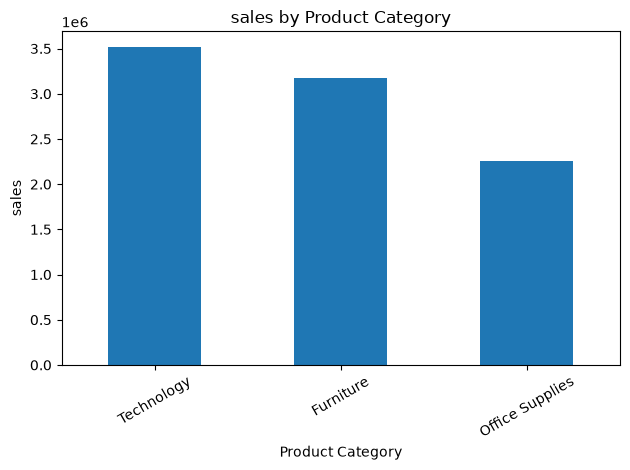

In [20]:
category_sales["Total_sales"].plot(
    kind ="bar",
    title ="sales by Product Category",
    ylabel ="sales",
    xlabel ="Product Category"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [21]:
segment_analysis = sales.groupby("Customer Segment").agg(
    Sales = ("Sales", "sum"),
    Profit =("Profit","sum"),
    Orders=("Order ID", "nunique")
).sort_values("Sales", ascending =False)

segment_analysis.round(2)

,Sales,Profit,Orders
Customer Segment,,,
Corporate,3269391.07,505538.63,2298
Home Office,2168952.03,283869.55,1598
Consumer,1835215.22,206559.63,1300
Small Business,1678373.00,316474.59,1264


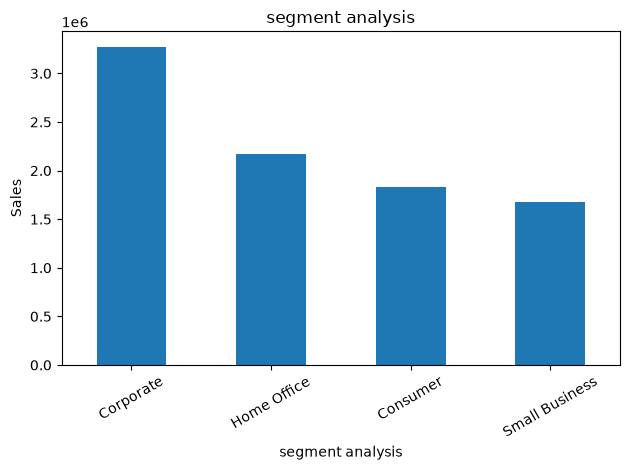

In [22]:
segment_analysis["Sales"].plot(
    kind ="bar",
    title ="segment analysis",
    ylabel ="Sales",
    xlabel ="segment analysis"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:
sales["Year"] =sales["Order Date"].dt.year
    
Yearly_analysis =sales.groupby("Year").agg(
Sales = ("Sales","sum"),
Profit = ("Profit","sum"),
Orders=("Order ID","nunique")
)
Yearly_analysis.round(2)

,Sales,Profit,Orders
Year,,,
2010,1924332.88,213324.14,1365
2011,1944507.43,297847.74,1454
2012,2230731.18,354073.57,1487
2013,2852359.83,447196.94,2185


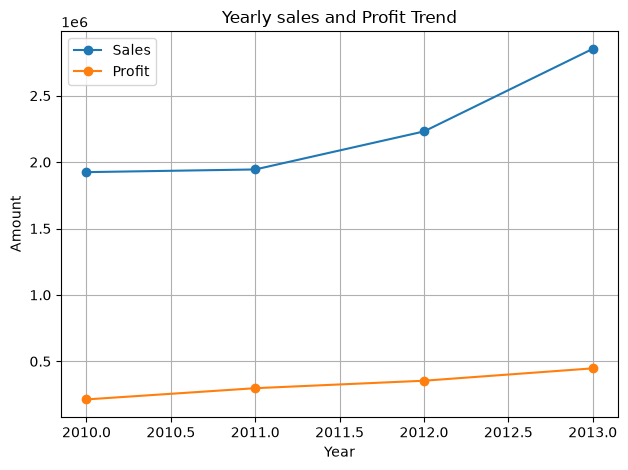

In [24]:
Yearly_analysis[["Sales","Profit"]].plot(
    kind ="line",
    marker = "o",
    title ="Yearly sales and Profit Trend",
)
plt.xlabel("Year")
plt.ylabel("Amount")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
Region_analysis =sales.groupby("Region").agg(
Sales =("Sales","sum"),
Profit =("Profit","sum"),
).sort_values("Sales", ascending =False)

Region_analysis.round(2)

,Sales,Profit
Region,,
Central,2540341.62,519825.57
East,2422804.68,377566.19
West,2391438.80,310849.45
South,1597346.22,104201.19


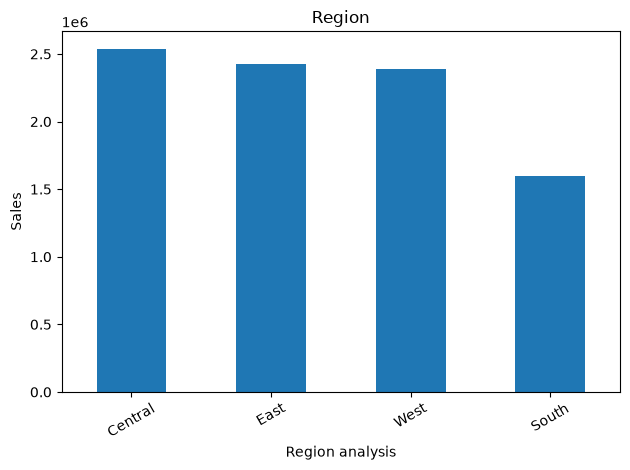

In [28]:
Region_analysis["Sales"].plot(
    kind = "bar",
    title ="Region",
ylabel ="Sales",
xlabel ="Region analysis"
)

plt.xticks(rotation =30)
plt.tight_layout()
plt.show()

In [32]:
top_customers =sales.groupby("Customer Name").agg(
Sales =("Sales","sum"),
Profit =("Profit","sum"),
Order =("Order ID","nunique")
).sort_values("Sales", ascending =False)

top_customers.head(10).round(2)

,Sales,Profit,Order
Customer Name,,,
Gordon Brandt,123745.62,7228.90,8
Glen Caldwell,89269.70,6469.93,15
Rosemary O'Brien,86540.75,7272.49,6
Leigh Burnette Hurley,83651.70,9289.94,13
Kristine Connolly,81296.39,4195.60,11
Nina Horne Kelly,78243.60,16432.45,4
Neal Wolfe,69118.00,5529.45,10
Priscilla Kane,61610.60,5504.26,9
Dana Teague,61298.98,4556.53,7


In [35]:
ship_analysis = sales.groupby("Ship Mode").agg(
    Sales =("Sales", "sum"),
    Profit =("Profit","sum"),
    Average_Ship_Date =("Ship Date", "mean")
).sort_values("Sales", ascending =False)

# Round only numeric columns to 2 decimal places
ship_analysis[["Sales","Profit"]] = ship_analysis[["Sales", "Profit"]].round(2)

ship_analysis

,Sales,Profit,Average_Ship_Date
Ship Mode,,,
Regular Air,4543658.96,893602.13,2012-03-11 05:29:05.764639
Delivery Truck,3706516.02,268061.91,2012-03-05 22:01:01.730319
Express Air,701756.34,150778.36,2012-02-17 05:10:53.658536


In [36]:
loss_making = sales[sales["Profit"] < 0]

print("Number of loss_making rows", len(loss_making))
print(

    "Total profit across loss-making rows:",
    round(loss_making["Profit"].sum(),2)

)

Number of loss_making rows 4558
Total profit across loss-making rows: -1162740.84


In [38]:
loss_making[
    [
        "Order ID",
        "Product Name",
        "Discount",
        "Sales",
        "Profit",
        "Customer Segment"
    ]
    ].sort_values("Profit").head(10)

,Order ID,Product Name,Discount,Sales,Profit,Customer Segment
4659,85865,5165,0.08,1486.34,-16476.83800,Corporate
4338,90534,Large Capacity Hanging Post Binders,0.01,81.31,-14369.12358,Home Office
7800,87317,Polycom ViewStation™ ISDN Videoconferencing Unit,0.09,6296.00,-14140.70160,Consumer
4844,87853,"Riverside Palais Royal Lawyers Bookcase, Royal...",0.04,6968.90,-13706.46400,Home Office
5402,91277,Polycom ViewStation™ ISDN Videoconferencing Unit,0.04,6569.07,-13562.63741,Home Office
5409,88799,Okidata Pacemark 4410N Wide Format Dot Matrix ...,0.05,3460.11,-10402.94392,Home Office
7725,89498,Polycom ViewStation™ ISDN Videoconferencing Unit,0.06,9507.12,-10263.65970,Consumer
2191,89896,Canon imageCLASS 2200 Advanced Copier,0.05,6849.48,-9078.94000,Consumer
4068,88853,Okidata Pacemark 4410N Wide Format Dot Matrix ...,0.06,3057.44,-8570.44830,Consumer
4857,90778,Okidata Pacemark 4410N Wide Format Dot Matrix ...,0.05,3360.30,-7961.43090,Corporate


In [42]:
subcategory_analysis=sales.groupby(
 "Product Sub-Category"
).agg(
    Sales=("Sales","sum"),
    Profit=("Profit","sum"),
Quantity=("Quantity ordered new","sum")
)
#Top 5 sub-category by Sales
subcategory_analysis.sort_values(
    "Sales", ascending=False
).head(5).round(2)

,Sales,Profit,Quantity
Product Sub-Category,,,
Office Machines,1218656.59,168072.83,4674
Chairs & Chairmats,1164584.16,165348.88,6325
Telephones and Communication,1144272.98,297950.52,14284
Tables,1061921.06,-72495.06,5187
Copiers and Fax,661211.93,129156.68,1177


In [43]:
subcategory_analysis.sort_values(
    "Profit",ascending=True
).head(5).round(2)

,Sales,Profit,Quantity
Product Sub-Category,,,
Tables,1061921.06,-72495.06,5187
Bookcases,507494.49,-7708.75,2694
Rubber Bands,8663.77,-2841.72,2755
"Scissors, Rulers and Trimmers",40428.87,-1936.85,2014
Pens & Art Supplies,103251.59,1195.90,10752
